In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as opt
from scipy.optimize import minimize
from scipy.optimize import linprog
from scipy.optimize import LinearConstraint
from sklearn.linear_model import LinearRegression
from datetime import datetime, timedelta
import torch
import torch.nn.functional as F
import math

def get_option_data(df, date_val, exdate_val):
    
    filtered_df = df[(df['date'] == int(date_val)) & (df['exdate'] == int(exdate_val))]
    result_df = filtered_df[['strike_price', 'cp_flag', 'best_bid', 'best_offer']]
    return result_df.to_numpy()

_spx_cache_df = pd.read_csv('spx_prices.csv', index_col=0, parse_dates=True)
_spx_cache = {
        int(pd.to_datetime(d).strftime('%Y%m%d')): float(v) 
        for d, v in _spx_cache_df['Close'].to_dict().items()
    }

def get_spx_close(date_val):
    try:
        d_int = int(date_val)
    except (ValueError, TypeError):
        return None

    # Direct lookup
    if d_int in _spx_cache:
        return _spx_cache[d_int]

    available_dates = sorted(_spx_cache.keys())
    past_dates = [d for d in available_dates if d <= d_int]

    if past_dates:
        return _spx_cache[past_dates[-1]]

    return None

def process_date_exdate(df, date_val, exdate_val):

    test = get_option_data(df, date_val, exdate_val)

    test_calls = test[test[:, 1] == 'C']
    test_puts = test[test[:, 1] == 'P']

    test_calls = np.delete(test_calls, 1, axis=1).astype(float)
    test_puts = np.delete(test_puts, 1, axis=1).astype(float)

    common_strikes = np.intersect1d(test_calls[:, 0], test_puts[:, 0])

    test_calls = test_calls[np.isin(test_calls[:, 0], common_strikes)]

    test_puts = test_puts[np.isin(test_puts[:, 0], common_strikes)]

    test_calls = test_calls[test_calls[:, 0].argsort()]
    test_puts = test_puts[test_puts[:, 0].argsort()]

    mid_calls = test_calls[:, 1:3].mean(axis=1)
    mid_puts = test_puts[:, 1:3].mean(axis=1)

    diff_prices = (mid_calls - mid_puts).reshape(-1, 1)

    test_avg = np.hstack((test_calls[:, [0]], diff_prices))

    X = test_avg[:, 0].reshape(-1, 1)
    y = test_avg[:, 1]

    model = LinearRegression()
    model.fit(X, y)

    B = model.coef_[0]
    A = model.intercept_

    y_pred = model.predict(X)

    lower_bound = test_calls[:, 1] - test_puts[:, 2]
    upper_bound = test_calls[:, 2] - test_puts[:, 1]

    within_bounds = (y_pred >= lower_bound) & (y_pred <= upper_bound)

    num_violations = np.sum(~within_bounds)

    if num_violations > 0:
        print("\nViolations found at these strikes:")
        violations_df = pd.DataFrame({
            'Strike': X.flatten()[~within_bounds],
            'Lower Bound': lower_bound[~within_bounds],
            'Predicted': y_pred[~within_bounds],
            'Upper Bound': upper_bound[~within_bounds]
        })
        display(violations_df)
        return None, None, None, None

    D = -B
    F = A/D

    spot = get_spx_close(date_val)
    if spot is None: return None, None, None, None
    spot_val = float(spot.iloc[0]) if hasattr(spot, 'iloc') else float(spot)

    strike_scale = spot_val / F
    price_scale = spot_val / (D * F)

    test_calls[:, 0] = test_calls[:, 0] * strike_scale
    test_calls[:, 1:3] = test_calls[:, 1:3] * price_scale

    test_puts[:, 0] = test_puts[:, 0] * strike_scale
    test_puts[:, 1:3] = test_puts[:, 1:3] * price_scale

    K = test_calls[:, 0]

    C_h = np.minimum(test_calls[:, 2], test_puts[:, 2] + spot_val - K)

    C_l = np.maximum(test_calls[:, 1], test_puts[:, 1] + spot_val - K)

    return K, C_l, C_h, spot_val

def load_theta(S, K, C_h, C_l, Kbar, S_prev=None, prev_sigs = None, prev_nus = None):
    N = len(K)
    L = 0.0
    dK = np.diff(K)
    
    # 1. Convexity Constraints (N-2 equations)
    A_conv = np.zeros((N - 2, N))
    A_conv[np.arange(N - 2), np.arange(N - 2)] = -1.0 / dK[:-1]
    A_conv[np.arange(N - 2), np.arange(1, N - 1)] = 1.0 / dK[:-1] + 1.0 / dK[1:]
    A_conv[np.arange(N - 2), np.arange(2, N)] = -1.0 / dK[1:]
    b_conv = np.zeros(N - 2)
    
    # 2. Monotonicity Constraints (N-1 equations)
    A_mon = np.zeros((N - 1, N))
    A_mon[np.arange(N - 1), np.arange(N - 1)] = -1.0
    A_mon[np.arange(N - 1), np.arange(1, N)] = 1.0
    b_mon = np.zeros(N - 1)
    
    # 3. Boundary Constraints (5 equations)
    A_bound = np.zeros((5, N))
    b_bound = np.zeros(5)
    
    A_bound[0, N - 1] = -1.0
    # b_bound[0] is already 0.0
    
    A_bound[1, 0] = -1.0
    b_bound[1] = K[0] - S
    
    A_bound[2, 0] = 1.0 / (K[0] - L) + 1.0 / dK[0]
    A_bound[2, 1] = -1.0 / dK[0]
    b_bound[2] = (S - L) / (K[0] - L)
    
    A_bound[3, N - 2] = -1.0 / dK[-1]
    A_bound[3, N - 1] = 1.0 / (Kbar - K[-1]) + 1.0 / dK[-1]
    # b_bound[3] is already 0.0
    
    A_bound[4, 0] = 1.0
    b_bound[4] = S - L
    
    # 4. Upper and Lower Bounds (Vectorized)
    lb = np.maximum.reduce([np.zeros(N), S - K, C_l])

    prev_c_vals1, prev_c_vals2 = None, None
    if S_prev is not None:
        prev_c_vals1, prev_c_vals2 = load_c_values(S_prev, prev_sigs, prev_nus)
        prev_lb = np.fromiter((V_K(S_prev, prev_sigs, prev_nus, prev_c_vals1, prev_c_vals2, k) + max(S_prev - k, 0) for k in K), dtype=float)
        print("previous lb:", prev_lb)
        lb = np.maximum(lb, prev_lb)

    ub = np.minimum(S, C_h)
    
    # 5. Dynamically stack all constraints: A @ x <= b
    # This replaces the error-prone hardcoded zero-matrix indexing
    A = np.vstack([A_conv, A_mon, A_bound, np.eye(N), -np.eye(N)])
    b = np.concatenate([b_conv, b_mon, b_bound, ub, -lb])
    
    # 6. Find initial feasible point
    # Objective is zero vector because we just need ANY point in the feasible region
    res = linprog(np.zeros(N), A_ub=A, b_ub=b)

    if not res.success:
        print("Initial point failure:", res.message)
        return None, None

    x0 = res.x

    # 7. Find Analytic Center (Maximize slack)
    def objective(x):
        slack = b - A @ x
        # Use log-sum to prevent float underflow, clamp to avoid log(0) NaN crashes
        return -np.prod(slack)

    constraint = LinearConstraint(A, lb=-np.inf, ub=b)
    
    result = minimize(
        objective, 
        x0, 
        method='trust-constr', 
        constraints=constraint
    )

    if result.success:
        C = result.x
        print("Objective:", objective(C))
        print("result:", C)
    else:
        print("Optimization failed:", result.message)
        return None, None
        
    def A_t(sigma,A,B,K):
        return 0.5 * ((A-sigma*B)*np.exp(-K/sigma) + (A+sigma*B)*np.exp(K/sigma))

    def B_t(sigma,A,B,K):
        return (1/(2 * sigma)) * (-(A-sigma*B)*np.exp(-K/sigma) + (A+sigma*B)*np.exp(K/sigma))

    def bisect(f, low, high, tol=1e-8):
        if f(low) < 0: return low
        elif f(high) > 0: return high
        while (high - low) > tol:
            mid = (low + high) / 2
            if mid == low or mid == high: return mid
            if f(mid) < 0:
                high = mid
            else:
                low = mid
        return (low + high) / 2

    def SigmaHat(A,B,K1,K2,V):
        my_eps = 1.0e-8
        def SigmaHat_obj(sigma): return A_t(sigma,A,B,K1) + B_t(sigma,A,B,K1)*K2 - V
        low = my_eps
        high = 1.0
        while (SigmaHat_obj(high) > 0): high = 2.0*high
        result = bisect(SigmaHat_obj, low, high)
        return result

    def SigmaTilde(sigma,A,B,K1,K2,V):
        my_eps = 1.0e-8
        At, Bt = A_t(sigma,A,B,K1), B_t(sigma,A,B,K1)
        def SigmaTilde_obj(sigma_t): return A_t(sigma_t,At,Bt,K2) - V
        low = my_eps
        high = 1.0
        while (SigmaTilde_obj(high) > 0): high = 2.0*high
        result = bisect(SigmaTilde_obj, low, high)
        return result

    def CalibrateTwoSigmas(A,B,K1,K2,V,B1):
        def TwoSigma_obj(sigma):
            sigma_t = SigmaTilde(sigma,A,B,K1,K2,V)
            At, Bt = A_t(sigma,A,B,K1), B_t(sigma,A,B,K1)
            return B1 - B_t(sigma_t,At,Bt,K2)
        low = SigmaHat(A,B,K1,K2,V)
        high = low + 1
        while (TwoSigma_obj(high) > 0): high = 2.0*high
        result = bisect(TwoSigma_obj, low, high)
        return result, SigmaTilde(result,A,B,K1,K2,V)

    def CalibrateThreeSigmas(A,B,K1,K2,K3,W,V,B1):
        sigma1 = SigmaHat(A,B,K1,K2,W)
        At, Bt = A_t(sigma1,A,B,K1), B_t(sigma1,A,B,K1)
        sigma2, sigma3 = CalibrateTwoSigmas(At,Bt,K2,K3,V,B1)
        return sigma1, sigma2, sigma3

    def Intersection_obj(K, A, B, x):
        return A + B * (x-K) - V_K(S_prev, prev_sigs, prev_nus, prev_c_vals1, prev_c_vals2, x)

    i0 = np.searchsorted(K, S)
    
    Lt1 = C[i0-1] + (S-K[i0-1])*(C[i0-1]-C[i0-2])/(K[i0-1]-K[i0-2])
    Lt2 = C[i0] + (S-K[i0])*(C[i0+1]-C[i0])/(K[i0+1]-K[i0])
    Lt = max([Lt1,Lt2])
    
    Ut = C[i0-1]*(K[i0]-S)/(K[i0]-K[i0-1]) + C[i0]*(S-K[i0-1])/(K[i0]-K[i0-1])
    
    delta = 0.5
    Vtemp = delta*Lt + (1-delta)*Ut
    
    K1 = np.concatenate(([L], K[:i0], [S]))
    V1 = np.concatenate(([0], C[:i0] - S + K[:i0], [Vtemp]))
    
    K2 = np.concatenate(([0], Kbar - K[i0:][::-1], [Kbar - S]))
    V2 = np.concatenate(([0], C[i0:][::-1], [Vtemp]))

    def CalibrationAlgorithm(K0, K1, A, V, B, B1):
        nu = []
        sigmas = []
        flag = False
        if S_prev is not None:
            cross1 = bisect(lambda x: Intersection_obj(K0, A, B, x), K0+1e-8, K1-1e-8)
            cross2 = bisect(lambda x: -Intersection_obj(K1, V, B1, x), K0+1e-8, K1-1e-8)
            flag = cross1 < cross2
        if flag:
            print(K0, K1, cross1, cross2)
            w1 = min((K1-K0)/3, cross1-K0)
            w2 = max((K1-K0)*2/3, cross2-K0)
            W = V + B1 * (w2+K0-K1)
            sigma1, sigma2, sigma3 = CalibrateThreeSigmas(A, B, w1, w2-w1, K1-K0-w2, W, V, B1)
            nu.append(K0)
            nu.append(K0+w1)
            nu.append(K0+w2)
            sigmas.append(sigma1)
            sigmas.append(sigma2)
            sigmas.append(sigma3)
        else:
            w = (V + B*K0 - A - B1*K1)/(B-B1)
            sigma1, sigma2 = CalibrateTwoSigmas(A, B, w-K0, K1-w, V, B1)
            nu.append(K0)
            nu.append(w)
            sigmas.append(sigma1)
            sigmas.append(sigma2)
        return nu, sigmas

    def Interpolate(K,V):
        N = len(K)
        nu = []
        sigmas = []
        delta = 0.5
        B = delta*(V[1]-V[0])/(K[1]-K[0])
        print("Slope diffs:", np.min(np.diff(np.diff(V)/np.diff(K))))
        
        for i in range(N-2):
            K0 = K[i]
            K1 = K[i+1]
            K2 = K[i+2]
            A = V[i]
            V1 = V[i+1]
            V2 = V[i+2]
            B1 = delta*(V2-V1)/(K2-K1) + (1.0-delta)*(V1-A)/(K1-K0)
            nus_new, sigmas_new = CalibrationAlgorithm(K0, K1, A, V1, B, B1)
            nu.extend(nus_new)
            sigmas.extend(sigmas_new)
            B=B1
        return nu, sigmas, B

    nu1, sigmas1, B1_last = Interpolate(K1,V1)
    nu2, sigmas2, B2_last = Interpolate(K2,V2)

    delta1 = 0.5
    rho = delta1 + delta1*(V2[-2]-V2[-1])/(K2[-1]-K2[-2]) + (1.0-delta1)*(V1[-1]-V1[-2])/(K1[-1]-K1[-2])

    K1t = K1[-2]
    K2t = K1[-1]
    A = V1[-2]
    V2t = V1[-1]
    B = B1_last
    B1 = rho
    nus_new, sigmas_new = CalibrationAlgorithm(K1t, K2t, A, V2t, B, B1)
    nu1.extend(nus_new)
    sigmas1.extend(sigmas_new)

    K1t = K2[-2]
    K2t = K2[-1]
    A = V2[-2]
    V2t = V2[-1]
    B = B2_last
    B1 = 1 - rho
    nus_new, sigmas_new = CalibrationAlgorithm(K1t, K2t, A, V2t, B, B1)
    nu2.extend(nus_new)
    sigmas2.extend(sigmas_new)

    sigs = np.concatenate([sigmas1, sigmas2[::-1]])
    nus = np.concatenate([nu1, [S], Kbar - np.array(nu2[::-1])])
    return sigs, nus

def load_c_values(S0, sigs, nus):
    # Ensure inputs are evaluated as Pynp operations
    R1 = np.searchsorted(nus, S0)
    nus1, sigs1 = nus[:R1+1], sigs[:R1]
    nus2, sigs2 = nus[R1:], sigs[R1:]

    c_vals1 = []
    dist0 = nus1[1] - nus1[0]
    # Use np.stack to combine scalars into a 1D tensor
    c_vals1.append(np.stack([-np.exp(-dist0/sigs1[0]), np.exp(dist0/sigs1[0])]))
    
    for i in range(len(sigs1) - 1):
        A = c_vals1[-1][0] + c_vals1[-1][1]
        B = (1/sigs1[i]) * (-c_vals1[-1][0] + c_vals1[-1][1])
        
        dist = nus1[i+2] - nus1[i+1]
        
        c_vals1.append(np.stack([
            0.5 * (A - sigs1[i+1]*B) * np.exp(-dist/sigs1[i+1]), 
            0.5 * (A + sigs1[i+1]*B) * np.exp(dist/sigs1[i+1])
        ]))

    # 2. Right side propagation
    c_vals2 = [None] * len(sigs2)
    dist_end = nus2[-1] - nus2[-2]
    c_vals2[-1] = np.stack([np.exp(dist_end/sigs2[-1]), -np.exp(-dist_end/sigs2[-1])])
    
    for i in range(len(sigs2) - 1, 0, -1):
        A = c_vals2[i][0] + c_vals2[i][1]
        B = (1/sigs2[i]) * (-c_vals2[i][0] + c_vals2[i][1])
        
        dist = nus2[i] - nus2[i-1]
        
        c_vals2[i-1] = np.stack([
            0.5 * (A - sigs2[i-1]*B) * np.exp(dist/sigs2[i-1]), 
            0.5 * (A + sigs2[i-1]*B) * np.exp(-dist/sigs2[i-1])
        ])
        
    # Stack the lists into 2D tensors
    c_vals1_tensor = np.stack(c_vals1)
    c_vals2_tensor = np.stack(c_vals2)

    # 3. Jump condition matching
    v1 = c_vals1_tensor[-1, 0] + c_vals1_tensor[-1, 1]
    Dk_v1 = (1/sigs1[-1]) * (-c_vals1_tensor[-1, 0] + c_vals1_tensor[-1, 1])
    
    v2 = c_vals2_tensor[0, 0] + c_vals2_tensor[0, 1]
    Dk_v2 = (1/sigs2[0]) * (-c_vals2_tensor[0, 0] + c_vals2_tensor[0, 1])
    
    denom = (Dk_v1 * v2 - v1 * Dk_v2)
    lam1, lam2 = v2 / denom, v1 / denom

    c_v1 = c_vals1_tensor * lam1
    c_v2 = c_vals2_tensor * lam2

    return c_v1, c_v2

def V_K(S0, sigs, nus, c_v1, c_v2, K):
    R1 = np.searchsorted(nus, S0)
    nus1, sigs1 = nus[:R1+1], sigs[:R1]
    nus2, sigs2 = nus[R1:], sigs[R1:]

    if K < nus[0]:
        return 0
    elif K > nus[-1]:
        return 0
    elif K < S0:
        idx = np.clip(np.searchsorted(nus1, K), 1, len(sigs1))
        dist = nus1[idx] - K
        sigma = sigs1[idx - 1]
        result = c_v1[idx - 1, 0] * np.exp(dist/sigma) + c_v1[idx - 1, 1] * np.exp(-dist/sigma)
    else:
        idx = np.clip(np.searchsorted(nus2, K, side='right'), 1, len(sigs2))
        dist = K - nus2[idx - 1]
        sigma = sigs2[idx - 1]
        result = c_v2[idx - 1, 0] * np.exp(-dist/sigma) + c_v2[idx - 1, 1] * np.exp(dist/sigma)
    
    return result

def validate_and_check_market(S0, sigs, nus, bid_ask_arr, plot=False):
    R1 = np.searchsorted(nus, S0)
    nus1, sigs1 = nus[:R1+1], sigs[:R1]
    nus2, sigs2 = nus[R1:], sigs[R1:]
    R2 = len(sigs2)
    
    c_v1, c_v2 = load_c_values(S0, sigs, nus)

    K_vec = bid_ask_arr[:, 0]
    mask_left = K_vec <= S0
    mask_right = ~mask_left
    results = np.zeros_like(K_vec)

    if np.any(mask_left):
        K_left = K_vec[mask_left]
        indices = np.searchsorted(nus1, K_left, side='left') - 1
        indices = np.clip(indices, 0, R1 - 1)
        dist = nus1[indices + 1] - K_left
        results[mask_left] = (c_v1[indices, 0] * np.exp(dist/sigs1[indices]) + c_v1[indices, 1] * np.exp(-dist/sigs1[indices])) + S0 - K_left

    if np.any(mask_right):
        K_right = K_vec[mask_right]
        indices = np.searchsorted(nus2, K_right, side='left') - 1
        indices = np.clip(indices, 0, R2 - 1)
        dist = K_right - nus2[indices]
        results[mask_right] = (c_v2[indices, 0] * np.exp(-dist/sigs2[indices]) + c_v2[indices, 1] * np.exp(dist/sigs2[indices]))

    return np.all((results >= bid_ask_arr[:, 1]) & (results <= bid_ask_arr[:, 2]))

def plot_V_K(S0, sigs, nus, ax=None, label=None):
    c_v1, c_v2 = load_c_values(S0, sigs, nus)
    K_vals = np.linspace(S0 - 200, S0 + 200, 1000)
    V_vals = np.array([V_K(S0, sigs, nus, c_v1, c_v2, k)+ max(S0-k,0) for k in K_vals])
    
    if ax is None: fig, ax = plt.subplots(figsize=(20, 8))
    ax.plot(K_vals, V_vals, label=str(label))
    ax.set_xlabel('K')
    ax.set_ylabel('V(K)')
    ax.set_title('Plot of $V(K)$ against $K$')
    ax.legend()
    ax.grid(True)

    if ax is None: plt.show()



In [20]:
import random

def plot_sigs(S0, sigs, nus, ax=None, label=None):
    random_color = (random.random(), random.random(), random.random())
    if ax is None: fig, ax = plt.subplots(figsize=(20, 8))
    first = True
    for i in range(len(sigs)):
        if nus[i] > 250:
            if first:
                ax.plot([np.log(nus[i]/S0), np.log(nus[i+1]/S0)], [sigs[i], sigs[i]], lw=0.5, color=random_color, label=str(label))
                first = False
            else: ax.plot([np.log(nus[i]/S0), np.log(nus[i+1]/S0)], [sigs[i], sigs[i]], lw=0.5, color=random_color)
            if (i != len(sigs)-1):
                ax.plot([np.log(nus[i+1]/S0), np.log(nus[i+1]/S0)], [sigs[i], sigs[i+1]], lw=0.5, color=random_color)
    ax.set_xlabel('log(K/S0)')
    ax.set_ylabel('Sigma')
    ax.set_title('Plot of sigmas')
    ax.legend()
    ax.grid(True)
    if ax is None: plt.show()

def test_date_index(INDEX, dataframe):
    df = dataframe.copy()
    df['dt_date'] = pd.to_datetime(df['date'], format='%Y%m%d')
    df['dt_exdate'] = pd.to_datetime(df['exdate'], format='%Y%m%d')

    date_counts = df.groupby('date')['exdate'].nunique()
    valid_dates = sorted(date_counts[date_counts > 0].index.tolist())
    
    if INDEX >= len(valid_dates):
        print(f"Index {INDEX} out of range for {len(valid_dates)} valid dates.")
        return
    
    target_date = valid_dates[INDEX]
    target_date_dt = pd.to_datetime(target_date, format='%Y%m%d')
    
    exdates = sorted(df[df['date'] == target_date]['exdate'].unique())

    prev_sigs, prev_nus, S0_prev= None, None, None

    Kbar = 0
    print(len(exdates))
    for exdate in exdates:
        exdate_dt = pd.to_datetime(exdate, format='%Y%m%d')
        K, C_l, C_h, S0 = process_date_exdate(dataframe, target_date, exdate)
        Kbar = max(Kbar, K[-1])

    Kbar += 400

    fig, axs = plt.subplots(2, 1, figsize=(20, 12))
    for i, exdate in enumerate(exdates):
        exdate_dt = pd.to_datetime(exdate, format='%Y%m%d')
        t_to_expiry = len(pd.bdate_range(target_date_dt, exdate_dt)) - 1
        K, C_l, C_h, S0 = process_date_exdate(dataframe, target_date, exdate)
        market_bid_ask = np.column_stack([K, C_l, C_h])
        sigs, nus = load_theta(S0, K, C_h, C_l, Kbar, S_prev=S0_prev, prev_sigs=prev_sigs, prev_nus=prev_nus)
        if nus is None:
            print("failed")
            continue
        if not validate_and_check_market(S0, sigs, nus, market_bid_ask):
            print("not valid")
            print("nus:", nus)
            continue
        plot_V_K(S0, sigs, nus, ax=axs[0], label=t_to_expiry)
        plot_sigs(S0, sigs, nus, ax=axs[1], label=t_to_expiry)
        prev_sigs = sigs
        prev_nus = nus
        S0_prev = S0
    plt.title(f"V(K) Surface Evolution for {target_date}")
    plt.legend()
    plt.show()
        


12
Objective: -9.066503504105321e-174
result: [2.33082593e+02 2.08067253e+02 1.83052776e+02 1.58039320e+02
 1.33027190e+02 1.08017048e+02 8.30107043e+01 6.80134546e+01
 6.30163538e+01 5.80211204e+01 5.30278060e+01 4.80365151e+01
 4.30474546e+01 3.80609286e+01 3.30788289e+01 2.81316568e+01
 2.32303977e+01 1.83867322e+01 1.37410514e+01 9.36833542e+00
 5.61068338e+00 2.66124208e+00 1.10657272e+00 4.00974797e-01
 2.11982401e-01 1.31428103e-01 8.74163140e-02 6.08421099e-02
 4.22630799e-02 3.27608314e-02 1.84621268e-02 1.14679305e-02]
Slope diffs: 3.154759605140156e-05
Slope diffs: 0.0002740434937889038
previous lb: [1.08358480e+03 9.83497302e+02 9.33453595e+02 8.83409927e+02
 8.33366303e+02 7.83322731e+02 7.33279218e+02 6.83235774e+02
 6.33192407e+02 6.08170756e+02 5.83149128e+02 5.63131839e+02
 5.58127518e+02 5.43114559e+02 5.33105923e+02 5.23097290e+02
 5.18092974e+02 5.13088659e+02 5.08084345e+02 5.03080032e+02
 4.98075719e+02 4.93071407e+02 4.88067095e+02 4.83062785e+02
 4.78058475e+02 

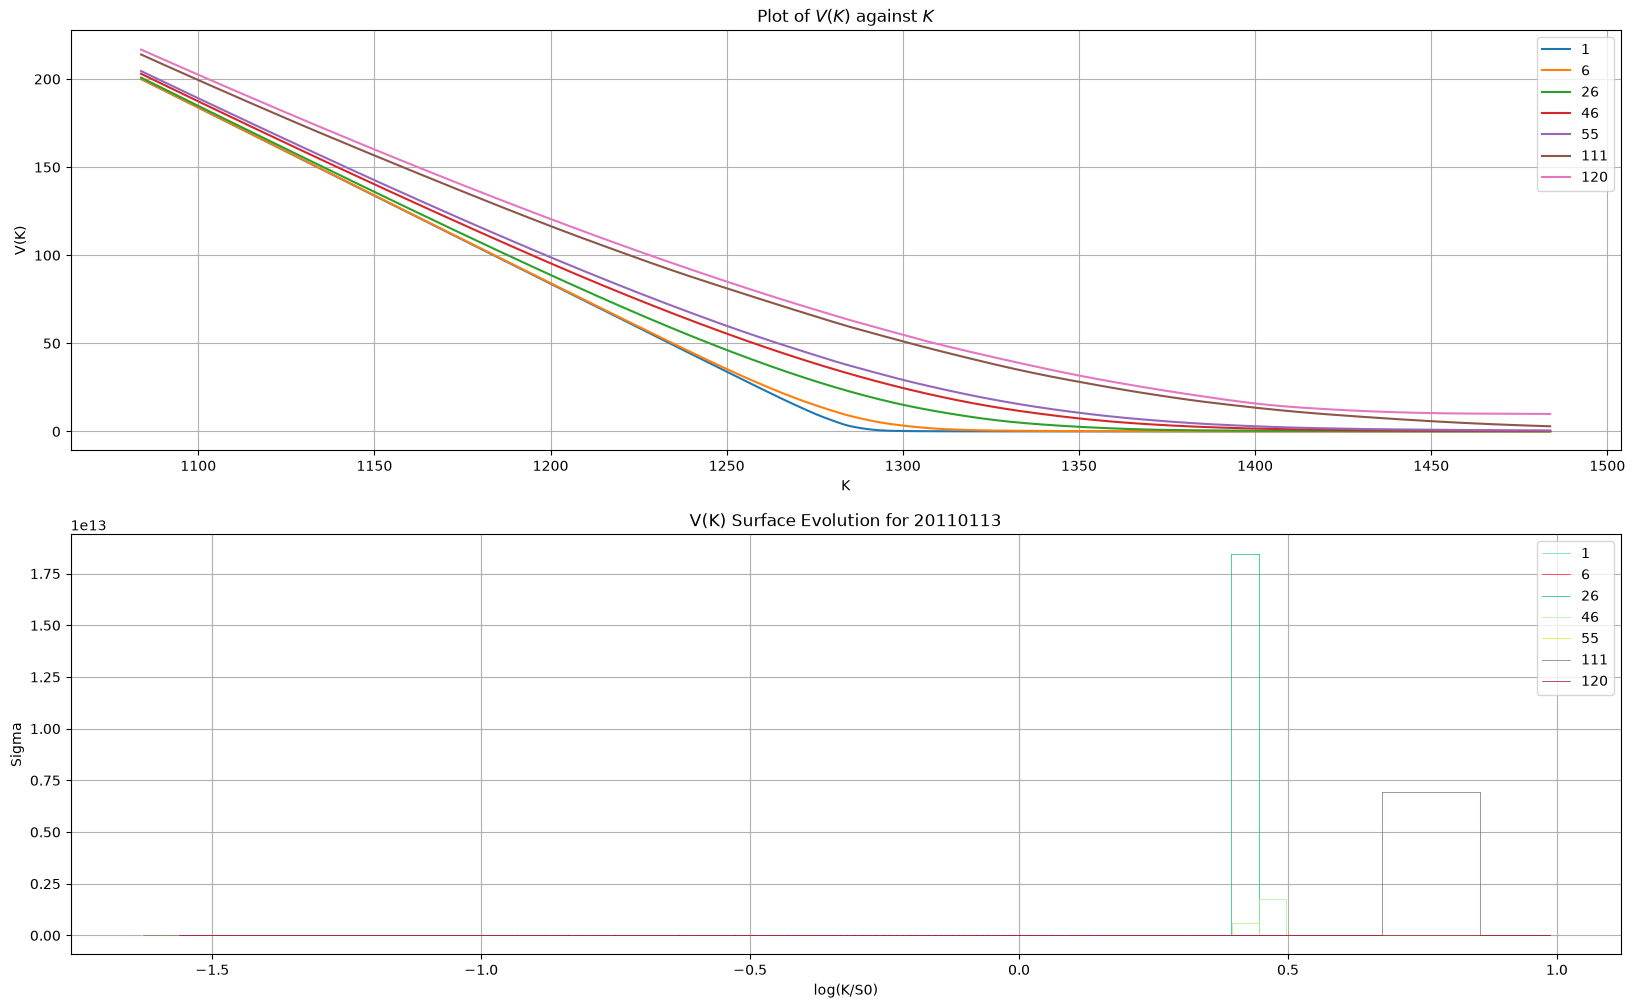

In [25]:
import warnings
warnings.filterwarnings('ignore')

dataframe = pd.read_csv("datasets/SPX_opt_2011_2012.csv")

test_date_index(8, dataframe)